# GMI Savings Tracker: a walkthrough of the evidence

**What this is.** Maryland's Government Modernization Initiative (GMI) reported savings and set a yearly savings target. This page checks those reports against the State's own payment records. It shows what the data supports, what it does not, and where to look next. It is also a worked example of how any government or school system could check its own savings claims. You do not need to read code to follow it.

**How to read it.**
- Start with *At a glance* and the key findings below; each section after them gives the evidence for one finding.
- Every number in the text is computed from the published tables in `site_data/` (the same files as the dashboard and the data release), so the text cannot drift from the data. The code for each step is folded under *Show the code*.
- Three kinds of figure are kept apart throughout: **reported** savings (GMI's own figures), what is **observed in payment data** (evidence, not verification), and **leads** (places worth a look, not savings).
- Fiscal years run July 1 to June 30 (FY2026 is July 2025 to June 2026). Budget years are plans, not outcomes.
- Terms such as *calibrated range* and *backtest* are explained in the [glossary](#Glossary).

In [1]:
import sys, subprocess, platform
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(root))
import yaml
import matplotlib
import pandas as pd
from IPython.display import HTML, Markdown, display
from src import published as P
from src.pipeline import overview_figures as V
cfg = yaml.safe_load((root / "config" / "assumptions.yaml").read_text())
info = P.run_info()
money = V.money
pct = lambda x: f"{x:.0%}"

## At a glance

In [2]:
st0 = P.load("d_savings_status")
wf0 = st0[st0.reported.notna()]
seen0, not0, none0 = wf0[wf0.status == "Seen"], wf0[wf0.status == "Not seen yet"], st0[st0.reported.isna()]
pl0 = P.load("d_plan50")
tgt0 = cfg["recommendations"]["target_saving"]
cov0 = V.coverage_summary().set_index(["scope", "calibrated"])
raw0 = cov0.loc[("in_sample", 0)]
ex = info["export"]
asof = f"{ex[:4]}-{ex[4:6]}-{ex[6:8]}"
portal = P.load("sources").portal_updated.max()
display(Markdown(f"""
**Data as of {asof}** (the six portal datasets were last updated on or before {portal}). Pipeline run {info['run_id']}; {info['checks']} automated checks, {info['passed']} passed.

**The bottom line.**
- Of {len(wf0)} reported savings items with a dollar figure, **{len(seen0)} show up in the State's payments** and **{len(not0)} do not yet**. Payments falling is evidence, not proof.
- The plan to reach the {money(tgt0)} target adds up to **{money(pl0.cumulative.iloc[-1])}**, but only **{money(pl0.saving.iloc[0])}** of that uses GMI's own reported rates. The rest rests on assumed rates that no recorded outcome has tested.
- The published forecast range was meant to hold 80% of outcomes but held **{raw0.coverage:.0%}**. A recalibrated range does better on years it had not seen (section 5).

**What this evidence could help a budget office, audit team or school-system finance office do.**
1. Ask for the dollar basis behind the {len(none0)} reported items that have no dollar figure.
2. Treat the leads as a review list with a named owner, and record each outcome, so that a real hit rate can be measured later.
3. Publish a checked forecast range beside every budget forecast.
4. Repeat the reported-against-payments check every year, so claims are tested as they are made.
"""))


**Data as of 2026-11-13** (the six portal datasets were last updated on or before 2026-11-09). Pipeline run 20261113T180346Z; 143 automated checks, 143 passed.

**The bottom line.**
- Of 5 reported savings items with a dollar figure, **3 show up in the State's payments** and **2 do not yet**. Payments falling is evidence, not proof.
- The plan to reach the $50M target adds up to **$52.6M**, but only **$29.6M** of that uses GMI's own reported rates. The rest rests on assumed rates that no recorded outcome has tested.
- The published forecast range was meant to hold 80% of outcomes but held **63%**. A recalibrated range does better on years it had not seen (section 5).

**What this evidence could help a budget office, audit team or school-system finance office do.**
1. Ask for the dollar basis behind the 7 reported items that have no dollar figure.
2. Treat the leads as a review list with a named owner, and record each outcome, so that a real hit rate can be measured later.
3. Publish a checked forecast range beside every budget forecast.
4. Repeat the reported-against-payments check every year, so claims are tested as they are made.


## Key findings

In [3]:
chk = P.load("run_checks")
s = P.load("f_scope")
base = s[s.scope == "Controllable purchases"].groupby(["fiscal_year", "stage"], as_index=False).budget.sum()
act, plan = base[base.stage == "Actual"], base[base.stage != "Actual"]
st = P.load("d_savings_status")
withfig = st[st.reported.notna()]
seen = withfig[withfig.status == "Seen"]
notseen = withfig[withfig.status == "Not seen yet"]
nofig = st[st.reported.isna()]
from src.models import forecast_published as FP
cov = V.coverage_summary().set_index(["scope", "calibrated"])
raw, cal = cov.loc[("in_sample", 0)], cov.loc[("out_of_sample", 1)]
opps = P.load("d_opps")
pl = P.load("d_plan50")
target = cfg["recommendations"]["target_saving"]
display(Markdown(f"""
1. **The base.** Controllable purchases, the part of the operating budget the savings work can act on, were **{money(act.budget.iloc[-1])} in FY{int(act.fiscal_year.iloc[-1])}**, the last year with actual spending. The FY{int(plan.fiscal_year.iloc[-1])} budget plans {money(plan.budget.iloc[-1])}; that is a plan, not an outcome. [Section 3](#3.-The-spending-base)
2. **Reported savings.** {len(st)} reported savings items can be paired with payments. Of the {len(withfig)} with a dollar figure, **{len(seen)} show up in the State's payments** ({money(seen.reported.sum())} reported) and **{len(notseen)} do not yet** ({money(notseen.reported.sum())} reported). For the {len(nofig)} without a figure, the data can only say whether payments fell. Payments falling is evidence, not proof. [Section 4](#4.-Reported-savings-against-the-State's-own-payments)
3. **Forecast ranges.** The published range was meant to hold 80% of outcomes but held only **{int(raw.hits)} of {int(raw.n)} past outcomes ({raw.coverage:.0%})**. A calibrated range published beside it held **{int(cal.hits)} of {int(cal.n)} ({cal.coverage:.0%})** when tested on years it had not seen (95% interval {cal.cov_lo:.0%} to {cal.cov_hi:.0%}). [Section 5](#5.-Forecasts,-and-how-far-to-trust-their-ranges)
4. **Leads.** Four detectors flag **{len(opps)} leads**. Applying assumed screening rates to the flagged spending gives {money(opps.low.sum())} to {money(opps.high.sum())}; these are places to look, not savings, and the ranges must not be added. [Section 6](#6.-Opportunities:-leads,-not-savings)
5. **The {money(target)} target.** A {len(pl)}-step path reaches **{money(pl.cumulative.iloc[-1])}** (range {money(pl.low.sum())} to {money(pl.high.sum())}); {money(pl.saving.iloc[0])} of it is GMI's own reported rates and the rest rests on assumed rates. [Section 7](#8.-The-path-to-the-target)
6. **Data quality.** {info['checks']} automated checks ran on this data: {info['passed']} passed, {info['warnings']} warned (the forecast range, finding 3) and {info['failed']} failed. [Sections 1 and 2](#1.-Where-the-data-came-from)
"""))


1. **The base.** Controllable purchases, the part of the operating budget the savings work can act on, were **$4.1B in FY2025**, the last year with actual spending. The FY2027 budget plans $4.8B; that is a plan, not an outcome. [Section 3](#3.-The-spending-base)
2. **Reported savings.** 12 reported savings items can be paired with payments. Of the 5 with a dollar figure, **3 show up in the State's payments** ($11.5M reported) and **2 do not yet** ($18.8M reported). For the 7 without a figure, the data can only say whether payments fell. Payments falling is evidence, not proof. [Section 4](#4.-Reported-savings-against-the-State's-own-payments)
3. **Forecast ranges.** The published range was meant to hold 80% of outcomes but held only **40 of 63 past outcomes (63%)**. A calibrated range published beside it held **53 of 63 (84%)** when tested on years it had not seen (95% interval 73% to 91%). [Section 5](#5.-Forecasts,-and-how-far-to-trust-their-ranges)
4. **Leads.** Four detectors flag **389 leads**. Applying assumed screening rates to the flagged spending gives $109M to $331M; these are places to look, not savings, and the ranges must not be added. [Section 6](#6.-Opportunities:-leads,-not-savings)
5. **The $50M target.** A 30-step path reaches **$52.6M** (range $42.6M to $64.2M); $29.6M of it is GMI's own reported rates and the rest rests on assumed rates. [Section 7](#8.-The-path-to-the-target)
6. **Data quality.** 143 automated checks ran on this data: 143 passed, 0 warned (the forecast range, finding 3) and 0 failed. [Sections 1 and 2](#1.-Where-the-data-came-from)


## 1. Where the data came from
Six datasets from the [Maryland Open Data Portal](https://opendata.maryland.gov/). Each download is compared with the portal's own row count; a mismatch stops the build.

In [4]:
src = P.load("sources")
t = src.assign(link=[f'<a href="https://opendata.maryland.gov/d/{i}">{i}</a>' for i in src.dataset_id],
               ok=src.reconciled.map({1: "Yes", 0: "No"}))
t = t[["title", "link", "years", "rows_portal", "rows_downloaded", "ok", "portal_updated"]]
t.columns = ["Dataset", "Portal ID", "Years", "Rows on portal", "Rows downloaded", "Counts match", "Portal updated"]
display(V.table(t, f"The {len(src)} source datasets (export {info['export']})", ints=["Rows on portal", "Rows downloaded"]))

Dataset,Portal ID,Years,Rows on portal,Rows downloaded,Counts match,Portal updated
State of Maryland Payments Data,7syw-q4cy,FY2008-FY2027,"412,880","412,880",Yes,2026-11-09
Maryland Operating Budget,yu65-jmmv,FY2017-FY2027,"741,957","741,957",Yes,2026-08-10
Maryland Operating Budget - Funding Source,gy87-e27x,FY2017-FY2027,"26,178","26,178",Yes,2026-08-10
State of Maryland Full Time Equivalents,x8qy-486w,FY2017-FY2027,"6,026","6,026",Yes,2026-08-10
State of Maryland Grant and Loan Data,absk-avps,FY2009-FY2025,"23,085","23,085",Yes,2026-10-09
Maryland Operating Budget: CUR and CR,4mca-332u,FY2017-FY2027,"84,446","84,446",Yes,2026-08-10


## 2. The checks
Each build runs automated checks on every layer of the data. A build that fails a *stop* check keeps the last good database and publishes nothing, so a broken download cannot reach this page.

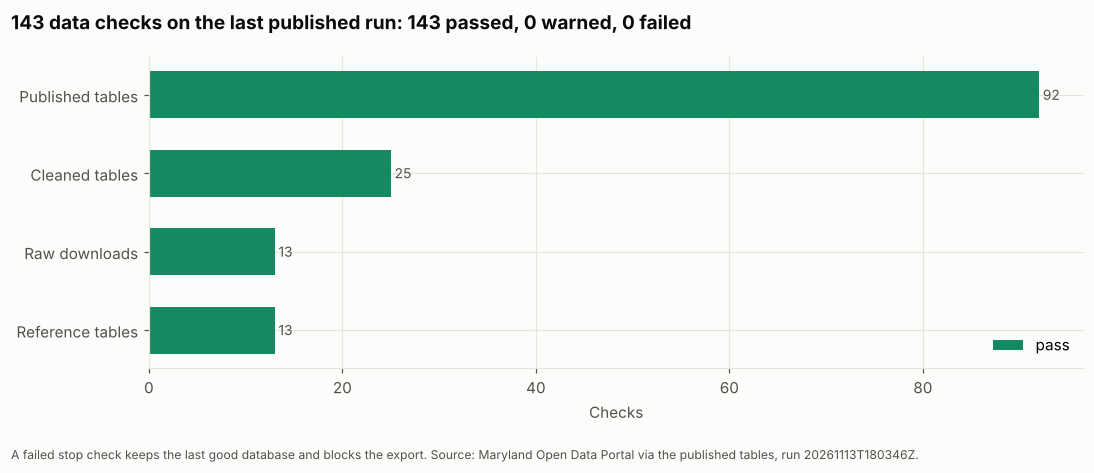

Stage,Check,Status,Detail


In [5]:
V.show("checks", "Bars count checks by pipeline stage: raw downloads, reference tables, the cleaned core tables and the published tables.")
bad = chk[chk.status != "pass"][["stage", "check", "status", "detail"]].assign(stage=lambda d: d.stage.map(V.STAGE).fillna(d.stage))
bad.columns = ["Stage", "Check", "Status", "Detail"]
display(V.table(bad, "Checks that did not pass"))

## 3. The spending base
Controllable purchases are the part of operating spending the savings work can act on: goods and services bought from vendors, not salaries, grants or debt service. Hatched bars are budgets (plans), not spending.

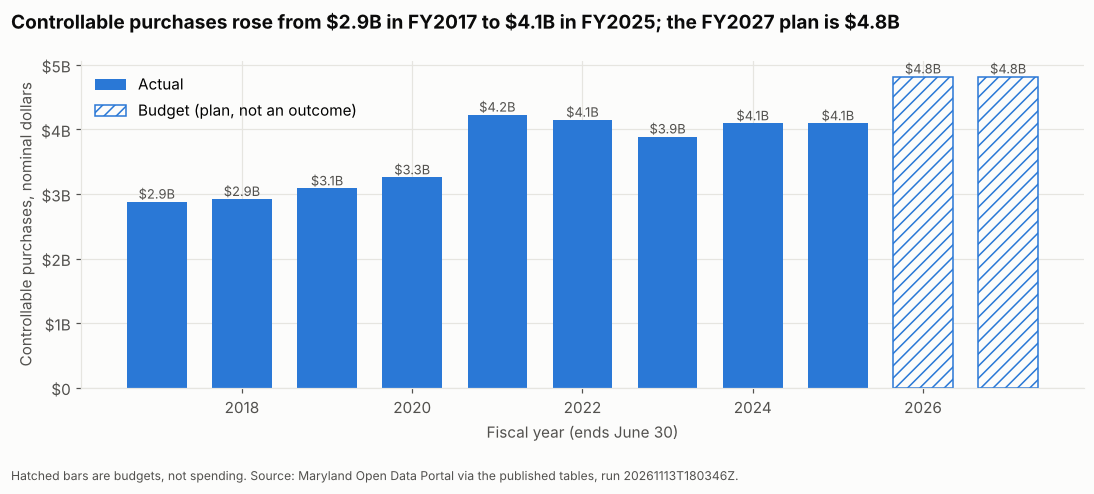

In [6]:
V.show("spending_base", f"Actual spending to FY{int(act.fiscal_year.iloc[-1])}; FY{int(plan.fiscal_year.min())} onward are budgets. Nominal dollars, not adjusted for inflation.")

## 4. Reported savings against the State's own payments
GMI reported savings items. For each, the tracker sums payments to the vendors that sell the thing being cut and compares the year before with the year after.

**How savings are counted here.** The tracker measures *payments*, meaning money that actually went out. It cannot see *cost avoidance* (a cost that would have grown but did not) or savings measured against a plan or appropriation; those need the agency's own baseline. The year-before against year-after comparison is a simple baseline: price changes, volume changes and one-time items can move payments for other reasons. The tracker cannot tell whether two reported items overlap. Where this page adds up dollars, they are the amounts GMI reported, and a sum of them is not a verified total.

How each status is assigned:

In [7]:
sc = cfg["savings"]
display(Markdown(f"""
| Status | When GMI gave a dollar figure |
|---|---|
| Seen | payments fell by at least {sc['seen_share']:.0%} of the reported saving, FY{sc['before_fy']} to FY{sc['after_fy']} |
| Partly seen | payments fell, but by less than that |
| Not seen yet | payments did not fall |

Where GMI gave no figure the status is only *Payments fell* or *Payments did not fall*; *Projected only* items are not due yet. **"Seen" means the payments move the way the claim implies; it is not an audit or a verification.** Payments can fall for other reasons, and a real saving measured against a plan, or bought on purchasing cards, may not show in payments at all (US GAO reports on claimed savings make the same distinction between reported and supported savings).
"""))


| Status | When GMI gave a dollar figure |
|---|---|
| Seen | payments fell by at least 50% of the reported saving, FY2025 to FY2026 |
| Partly seen | payments fell, but by less than that |
| Not seen yet | payments did not fall |

Where GMI gave no figure the status is only *Payments fell* or *Payments did not fall*; *Projected only* items are not due yet. **"Seen" means the payments move the way the claim implies; it is not an audit or a verification.** Payments can fall for other reasons, and a real saving measured against a plan, or bought on purchasing cards, may not show in payments at all (US GAO reports on claimed savings make the same distinction between reported and supported savings).


ID,Reported item,Reported saving,Payments FY2025,Payments FY2026,Change,Status
S01,Review and update agreements with seven vendors (~$81M annual spend),$18M,$86.4M,$96.4M,+$10.1M,Not seen yet
S02,Food services contract at one agency,not stated,$38M,$32.5M,-$5.5M,Payments fell
S03,Statewide radio system maintenance,not stated,$14.1M,$20.9M,+$6.8M,Payments did not fall
S04,Office supplies (DGS Office of State Procurement contract),not stated,$310K,$161K,-$149K,Payments fell
S05,Software Enterprise License Agreement (DoIT),not stated,$34M,$42.9M,+$8.9M,Payments did not fall
S06,Paused vehicle purchases (196 of 538 appropriated),$8M,$28.9M,$21.2M,-$7.6M,Seen
S08,Fuel and maintenance for a smaller fleet,$800K,$93.5M,$101M,+$7.4M,Not seen yet
S10,End low-use mobile phone lines,$500K,$4M,$3.4M,-$547K,Seen
S12,Cancel unused copper landlines,not stated,$33.9M,$39.9M,+$6M,Projected only
S13,Laptop refresh moved from 3 to 5 years (DoIT agencies),$3M,$61.4M,$54.8M,-$6.7M,Seen


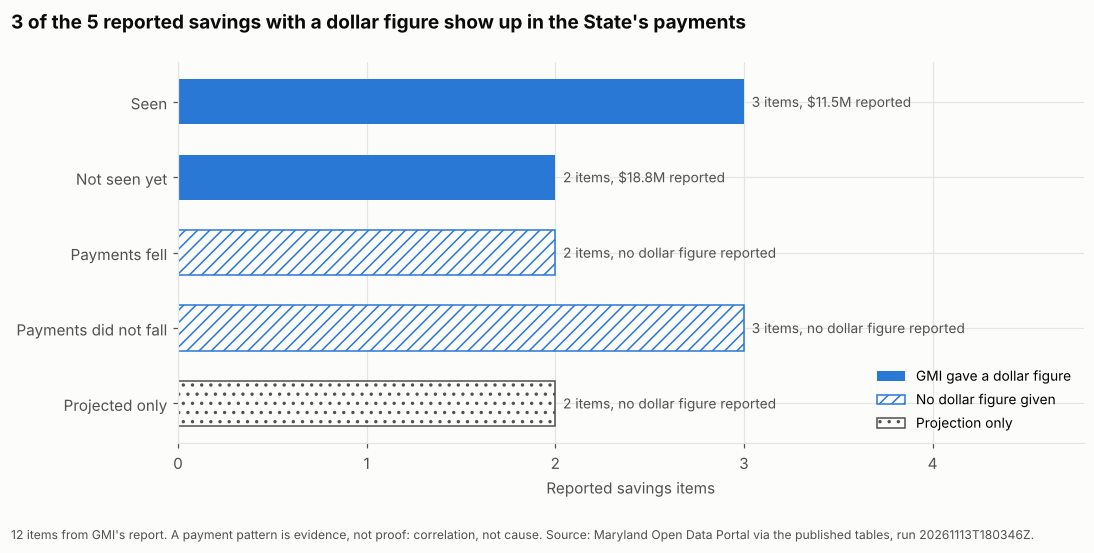

In [8]:
items = st.assign(change=st["after"] - st["before"])[["check_id", "item", "reported", "before", "after", "change", "status"]]
items.columns = ["ID", "Reported item", "Reported saving", f"Payments FY{sc['before_fy']}", f"Payments FY{sc['after_fy']}", "Change", "Status"]
display(V.table(items, "Each reported savings item and the matching payments", money=list(items.columns[2:5]), signed=["Change"]))
V.show("savings_status", "Each bar counts reported savings items by what the payments show. Solid bars are items with a reported dollar figure.")

## 5. Forecasts, and how far to trust their ranges
Each focus area gets the simplest model that wins a rolling backtest (forecasting past years from earlier data). The published range is the 10th to 90th percentile of bootstrap paths, so it is meant to hold 80% of outcomes. The backtest shows it holds fewer, so a **calibrated range** is published beside it: the raw range widened around the median by a factor fitted on past misses (conformal calibration). The raw columns are unchanged.

The next step rebuilds the forecast from three published input tables using the pipeline's own code, and stops if the result differs from the published forecast in any row. This is the one place the walkthrough runs model code; it refits nothing.

In [9]:
tables = V.rebuilt()
diffs = FP.differences(tables)
assert not diffs, diffs
print(f"Rebuilt forecast equals the published forecast: {len(tables['f_forecast'])} rows, 0 differences.")
m = P.load("d_forecast_model")[["area", "method", "growth", "backtest_mape", "baseline_fy2025"]]
m["growth"] = m.growth.where(m.method == "Log-linear trend")  # the naive model carries the last actual forward: no growth
m.columns = ["Focus area", "Model chosen", "Yearly growth (trend model only)", "Backtest error (MAPE)", "FY2025 actual"]
display(V.table(m, "The model chosen for each focus area", pct=["Yearly growth (trend model only)", "Backtest error (MAPE)"],
                money=["FY2025 actual"], na=""))

Rebuilt forecast equals the published forecast: 105 rows, 0 differences.


Focus area,Model chosen,Yearly growth (trend model only),Backtest error (MAPE),FY2025 actual
Fleet & fuel,Naive (last actual),,22.2%,$193M
"IT hardware, software & services",Naive (last actual),,3.7%,$692M
Other controllable purchases,Naive (last actual),,7.8%,$2.8B
"Print, copy & mail",Naive (last actual),,8.6%,$52.4M
Real estate & leases,Log-linear trend,1.4%,3.1%,$142M
Telecom,Naive (last actual),,6.7%,$46.8M
Utilities & facility energy,Naive (last actual),,11.4%,$162M


Test design,Range,Forecasts,Outcomes inside,Coverage,95% interval low,95% interval high,Widening factor
All past outcomes (in sample),Raw,63,40,63.5%,51.1%,74.3%,1.00
All past outcomes (in sample),Calibrated,63,52,82.5%,71.4%,90.0%,1.63
Each outcome year held out,Raw,63,37,58.7%,46.4%,70.0%,1.00
Each outcome year held out,Calibrated,63,53,84.1%,73.2%,91.1%,1.96
Only outcomes known at the time,Raw,42,19,45.2%,31.2%,60.1%,1.00
Only outcomes known at the time,Calibrated,42,41,97.6%,87.7%,99.6%,5.46


The raw range held 40 of 63 past outcomes (63.5%) against a target of 80%. Calibrated and tested with each outcome year held out, it held 53 of 63 (84.1%; 95% interval 73% to 91%). Using only outcomes known at each forecast date, it held 41 of 42 (97.6%) with a mean widening factor of 5.5: too wide, because early dates had few misses to learn from.

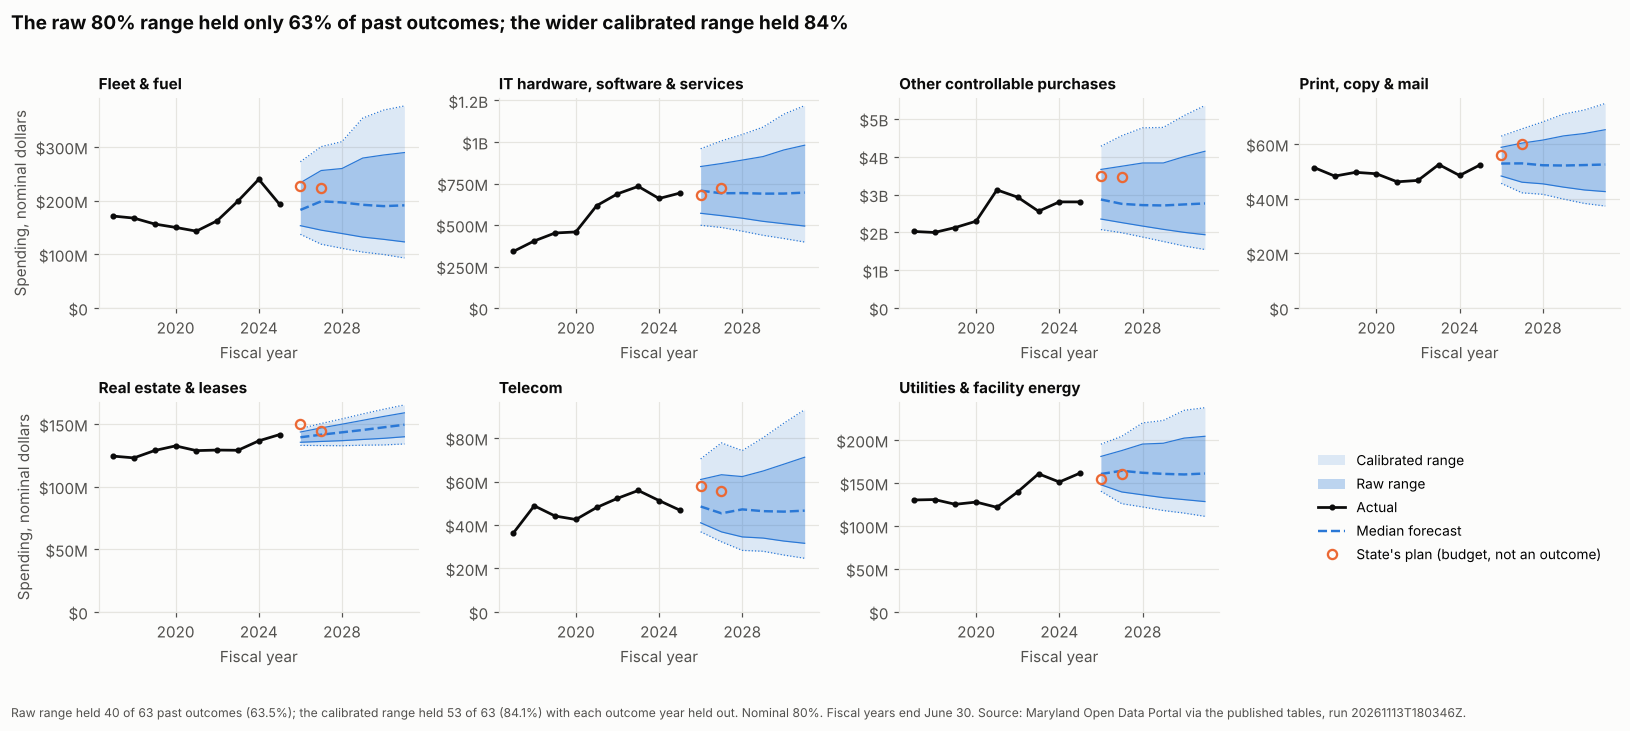

In [10]:
c = V.coverage_summary().copy()
c["scope"] = c.scope.map({"in_sample": "All past outcomes (in sample)", "out_of_sample": "Each outcome year held out",
                          "expanding_origin": "Only outcomes known at the time"})
c["calibrated"] = c.calibrated.map({0: "Raw", 1: "Calibrated"})
c = c[["scope", "calibrated", "n", "hits", "coverage", "cov_lo", "cov_hi", "factor"]]
c.columns = ["Test design", "Range", "Forecasts", "Outcomes inside", "Coverage", "95% interval low", "95% interval high", "Widening factor"]
display(V.table(c, "How often past outcomes fell inside the range (target: 80%)", pct=["Coverage", "95% interval low", "95% interval high"], dec=["Widening factor"]))
e = cov.loc[("expanding_origin", 1)]
display(Markdown(f"The raw range held {int(raw.hits)} of {int(raw.n)} past outcomes ({raw.coverage:.1%}) against a target of 80%. "
                 f"Calibrated and tested with each outcome year held out, it held {int(cal.hits)} of {int(cal.n)} ({cal.coverage:.1%}; 95% interval "
                 f"{cal.cov_lo:.0%} to {cal.cov_hi:.0%}). Using only outcomes known at each forecast date, it held {int(e.hits)} of {int(e.n)} "
                 f"({e.coverage:.1%}) with a mean widening factor of {e.factor:.1f}: too wide, because early dates had few misses to learn from."))
V.show("forecast_fan", "Black: actual spending. Dashed: median forecast. Dark band: raw 80% range; light band: calibrated range. Orange circles: the State's budget, a plan rather than an outcome.")

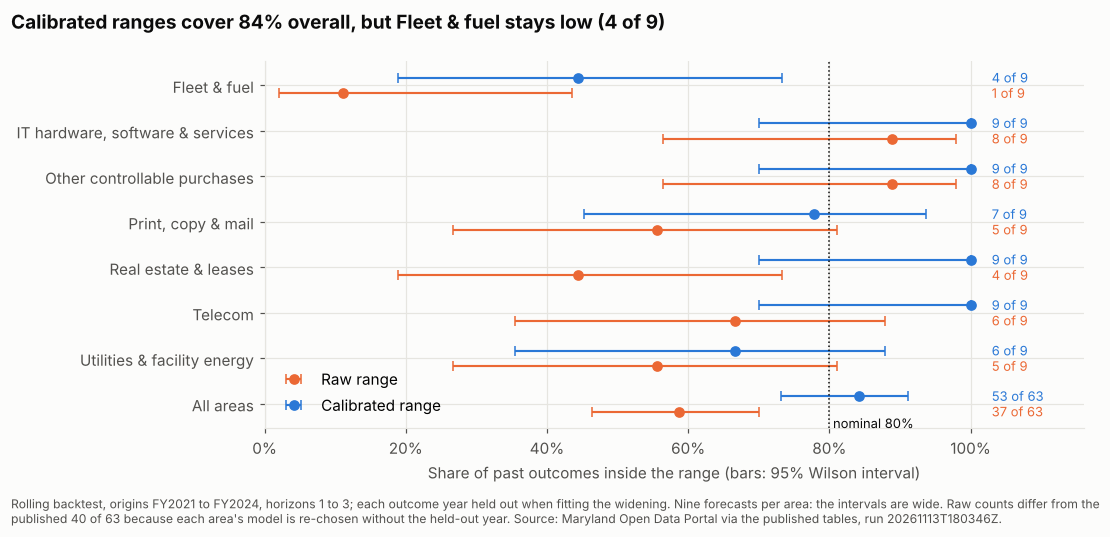

**Reading it.** Tested on held-out years, the calibrated range covers about what it claims, and its 95% interval includes 80%. It is one pooled correction, so areas differ: Fleet & fuel stays under-covered (4 of 9) because its model misses by more than a wider range can absorb. With 63 forecasts across 7 areas that share economic shocks, treat the calibrated range as a better-supported indication, not a guarantee.

In [11]:
rc = V.rebuilt()["d_range_coverage"]
rc = rc[(rc.source == "bootstrap") & (rc.horizon == 0) & (rc.scope == "out_of_sample") & (rc.calibrated == 1) & (rc.area != "All areas")]
worst = rc.sort_values("coverage").iloc[0]
V.show("range_coverage", "Dots: share of past outcomes inside the range; bars: 95% Wilson interval. The dotted line marks the 80% target.")
display(Markdown(f"""**Reading it.** Tested on held-out years, the calibrated range covers about what it claims, and its 95% interval includes 80%. It is one pooled correction, so areas differ: {worst.area} stays under-covered ({int(worst.hits)} of {int(worst.n)}) because its model misses by more than a wider range can absorb. With {int(cal.n)} forecasts across {rc.area.nunique()} areas that share economic shocks, treat the calibrated range as a better-supported indication, not a guarantee."""))

**Would a machine-learning model give better ranges?** A LightGBM quantile model (a gradient-boosted model trained across all areas) was backtested as a challenger on many agency-level spending series (so its figures are not comparable with the area table above). On that test its 80% ranges come closer to 80% than the naive model's raw ranges, but still fall short, so they are not simply swapped in: the tracker adopts LightGBM per agency–code series only where it beats naive in that series' own backtest, and the registry and the Forecasts tab show the adopted count.

In [12]:
cb0 = P.load("d_challenger_backtest")
cb = cb0.pivot(index="origin_fy", columns="model", values="coverage_80").reset_index()
cb = cb.rename(columns={"origin_fy": "Forecast made in FY"})
cb.insert(1, "Series scored", cb0.groupby("origin_fy").series_scored.max().to_numpy())
display(V.table(cb, "Share of outcomes inside the 80% range, by model and forecast year", ints=["Series scored"], pct=[c for c in cb.columns[2:]]))

Forecast made in FY,Series scored,LightGBM quantile (global),Naive (last actual)
2022,"2,173",72.0%,33.0%
2023,"2,178",74.0%,44.0%
2024,"2,161",74.0%,53.0%


## 6. Opportunities: leads, not savings
Four detectors flag spending worth a closer look:
- **Growth above trend**: an agency's spending on a budget code grew much faster than the State's spending on the same code.
- **Peer gap**: an agency spends more per budgeted position on a code than most comparable agencies.
- **Leverage**: one vendor is paid separately by many agencies, a candidate for a single statewide contract.
- **Tail spend**: payments in a focus area to vendors outside its largest suppliers.

The dollar ranges apply assumed screening percentages (set in `config/assumptions.yaml`) to the flagged spending. They are not forecasts, and detectors can look at the same spending from different angles, so the ranges must not be added up.

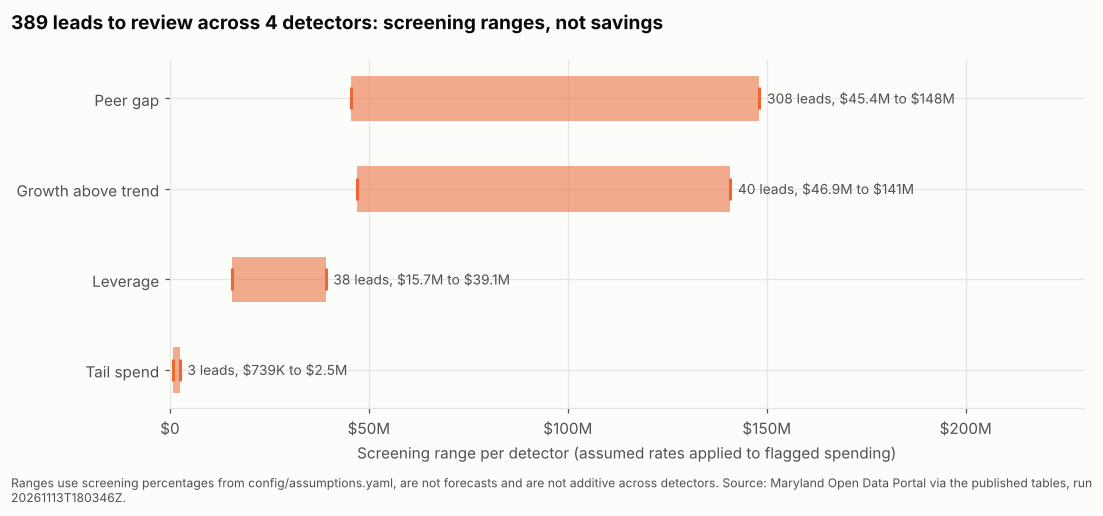

ID,Detector,Agency,Spending,Why it was flagged,Screening low,Screening high
O001,Growth above trend,Department of Transportation,Other Contractual Services-Non DP (899),grew +31% over FY2022-FY2025 vs -13% statewide,$17.5M,$52.5M
O002,Growth above trend,Maryland Department of Health,Food (920),grew +2090% over FY2022-FY2025 vs +141% statewide,$8.8M,$26.5M
O003,Growth above trend,Department of Human Services,Other Contractual Services-Non DP (899),grew +46% over FY2022-FY2025 vs -13% statewide,$6.9M,$20.8M
O004,Peer gap,Department of Human Services,Outside Services Programming (866),"$15,992 per position vs $4,406 at the 75th percentile of 14 agencies statewide (median $312); agencies differ in mission, so only 5-15% of the excess is counted",$2.9M,$9.6M
O005,Peer gap,Department of Transportation,Management Studies and Consultants (821),"$10,963 per position vs $5,283 at the 75th percentile of the 10 agencies in its spending-mix peer group (Other controllable purchases / IT hardware, software & services) (median $2,560); agencies differ in mission, so only 5-15% of the excess is counted",$3.1M,$9.3M
O006,Peer gap,Department of Information Technology,Outside Services-Consulting Services (872),"$389,101 per position vs $19,775 at the 75th percentile of the 15 agencies in its spending-mix peer group (Other controllable purchases / IT hardware, software & services) (median $1,611); agencies differ in mission, so only 5-15% of the excess is counted",$2.6M,$8.8M
O007,Peer gap,Department of Transportation,Security Services (823),"$5,765 per position vs $593 at the 75th percentile of the 10 agencies in its spending-mix peer group (Other controllable purchases / IT hardware, software & services) (median $335); agencies differ in mission, so only 5-15% of the excess is counted",$1.9M,$6.3M
O008,Growth above trend,Maryland Health Benefit Exchange,Other Contractual Services-Non DP (899),grew +32% over FY2022-FY2025 vs -13% statewide,$2M,$6.1M
O009,Peer gap,Department of Transportation,Building/Road Repair and Maintenance (812),"$5,147 per position vs $846 at the 75th percentile of the 13 agencies in its spending-mix peer group (Other controllable purchases / IT hardware, software & services) (median $397); agencies differ in mission, so only 5-15% of the excess is counted",$1.7M,$5.6M
O010,Peer gap,Department of Transportation,Equipment Repairs and Maintenance (809),"$5,124 per position vs $954 at the 75th percentile of the 12 agencies in its spending-mix peer group (Other controllable purchases / IT hardware, software & services) (median $418); agencies differ in mission, so only 5-15% of the excess is counted",$1.7M,$5.6M


In [13]:
V.show("opportunities", "Each bar runs from the low to the high screening estimate for one detector.")
top = opps.sort_values("high", ascending=False).head(10)[["opp_id", "detector", "agency", "spending_code", "evidence", "low", "high"]]
top.columns = ["ID", "Detector", "Agency", "Spending", "Why it was flagged", "Screening low", "Screening high"]
display(HTML("<details><summary>The ten leads with the largest screening ranges</summary>"
             + V.table(top, "The ten leads with the largest screening ranges", money=["Screening low", "Screening high"], na="").to_html() + "</details>"))

## 7. Every program, screened the same way
In November 2026 the press reported child care overpayments at the State Department of Education that the tracker had not found, and could not have: they are provider-level findings from internal audits, and the open data has one total per payee and year. But the program stood out in the budget data. This section applies that reading to every program of every agency: how many times it grew, its largest swing from one year to the next, and the audit findings on file beside it. It is an order in which to ask questions, not a finding.

In [14]:
ps = V.program_screen_table()
both = ps[ps.signals == 2]
print(f"{len(ps)} programs screened across {ps.agency_code.nunique()} agencies; {len(both)} crossed both thresholds, {int((ps.signals == 1).sum())} crossed one.")
cc = ps[ps.program_name.str.contains("Child Care Assistance")].iloc[0]
print(f"Child care grants: {V.money(cc.spend_first)} in FY{cc.first_fy} to {V.money(cc.spend_last)} in FY{cc.last_fy} ({cc.growth_multiple:.1f}x), "
      f"largest swing {cc.largest_swing:+.0%} in FY{cc.swing_fy}; rank {list(both.index).index(cc.name) + 1} of {len(both)} by size among programs with both signals.")
top = both.head(12)[["agency_code", "program_name", "spend_last", "growth_multiple", "largest_swing", "ola_findings", "ola_repeat_findings", "reported_amount", "recoupment_status"]]
top.columns = ["Agency", "Program", "Spending, last year", "Growth multiple", "Largest swing", "OLA findings", "OLA repeat findings", "Reported amount", "Recoupment status"]
display(V.table(top, "The twelve largest programs that crossed both thresholds", money=["Spending, last year", "Reported amount"], dec=["Growth multiple"], pct=["Largest swing"], ints=["OLA findings", "OLA repeat findings"]))
V.program_screen();

298 programs screened across 50 agencies; 75 crossed both thresholds, 83 crossed one.
Child care grants: $76.9M in FY2017 to $562M in FY2025 (7.3x), largest swing +154% in FY2022; rank 6 of 75 by size among programs with both signals.


Agency,Program,"Spending, last year",Growth multiple,Largest swing,OLA findings,OLA repeat findings,Reported amount,Recoupment status
M00,Community Services,$3.2B,3.09,37.1%,12,6,not stated,not stated
M00,Medicaid Behavioral Health Provider Reimbursements,$3.1B,2.64,39.8%,12,6,not stated,not stated
D50,Maryland Emergency Management Agency,$930M,8.22,1056.6%,not stated,not stated,not stated,not stated
M00,Maryland Children's Health Program,$610M,2.62,32.4%,12,6,not stated,not stated
D78,Reinsurance Program,$595M,15.05,-47.2%,not stated,not stated,not stated,not stated
R00,Child Care Assistance Grants,$562M,7.31,153.7%,11,0,$66.5M,Not recouped: agency decided not to seek repayment; Not stated
Y01,Revenue Stabilization Account,$500M,3.22,8444.6%,not stated,not stated,not stated,not stated
J00,Washington Metropolitan Area Transit-Capital,$351M,2.77,97.8%,6,0,not stated,not stated
Y01,Dedicated Purpose Account,$242M,40.42,1881.0%,not stated,not stated,not stated,not stated
D13,Renewable and Clean Energy Programs and Initiatives,$165M,10.33,139.1%,not stated,not stated,not stated,not stated


In [15]:
rep = V.PS.reported_findings()
shown = rep[["finding_id", "agency_code", "program_name", "finding", "amount", "period", "recoupment_status", "confirmation"]].copy()
shown["amount"] = pd.to_numeric(shown.amount, errors="coerce")
shown.columns = ["Finding", "Agency", "Program", "What was reported", "Amount", "Period", "Recoupment status", "Confirmation"]
display(V.table(shown, "Reported findings tied to a budget program (from the audit register)", money=["Amount"]))
V.childcare_program();

Finding,Agency,Program,What was reported,Amount,Period,Recoupment status,Confirmation
MSDE-CCS-2026-01,R00,Child Care Assistance Grants,Suspected overpayments to child care providers,$66.5M,2023-2025,Not stated,Reported; audit not public
MSDE-CCS-2026-02,R00,Child Care Assistance Grants,"Overpayments from agency implementation errors: 2,227 providers, average $4,479",$10.7M,2023-2025,Not recouped: agency decided not to seek repayment,Reported; agency statement


**Reading it.** Many of the flagged programs have ordinary explanations: federal relief money in FY2021 and FY2022, reserve accounts that are filled and emptied by design, a new law phasing in. The screen does not know which. Reported findings come from the audit register (`reference/audit_findings.csv`) and are tied to a budget program only where the source names one; two are, both for the child care program, taken from press reports because the audit documents are not public.

## 8. The path to the target

In [16]:
pl2 = pl.assign(kind=pl.step.map(lambda s: "1. GMI's reported rates on forecast spending" if s == 1 else None))
pl2.loc[pl.basis.str.contains("paid by"), "kind"] = "2. Statewide contracts with vendors many agencies use (assumed 2-5%)"
pl2.loc[pl.basis.str.contains("of forecast FY"), "kind"] = "3. Assumed 1% of forecast spending in remaining areas"
g = pl2.groupby("kind", as_index=False).agg(steps=("step", "size"), saving=("saving", "sum"), low=("low", "sum"), high=("high", "sum"))
g.columns = ["Kind of step", "Steps", "Central", "Low", "High"]
display(Markdown(f"The target is **{money(target)} a year**. The plan table stacks GMI's own reported rates first, then the largest leads. "
                 f"Each step names its basis; steps resting on assumed rates say so."))
display(V.table(g, f"The {len(pl)}-step path to {money(target)}, by kind of step", money=["Central", "Low", "High"]))
full = pl[["step", "action", "basis", "saving", "cumulative"]]
full.columns = ["Step", "Action", "Basis", "Saving", "Running total"]
display(HTML(f"<details><summary>All {len(pl)} steps</summary>" + V.table(full, "Every step of the path", money=["Saving", "Running total"]).to_html() + "</details>"))
display(Markdown(f"After {len(pl)} steps the central estimate is {money(pl.cumulative.iloc[-1])}, of which {money(pl.saving.iloc[0])} "
                 f"({pl.saving.iloc[0] / pl.cumulative.iloc[-1]:.0%}) comes from GMI's own reported rates; the rest depends on assumed rates "
                 f"that no recorded outcome has yet tested."))

The target is **$50M a year**. The plan table stacks GMI's own reported rates first, then the largest leads. Each step names its basis; steps resting on assumed rates say so.

Kind of step,Steps,Central,Low,High
1. GMI's reported rates on forecast spending,1,$29.6M,$29.6M,$29.6M
2. Statewide contracts with vendors many agencies use (assumed 2-5%),27,$19.9M,$11.4M,$28.5M
3. Assumed 1% of forecast spending in remaining areas,2,$3.1M,$1.5M,$6.1M


Step,Action,Basis,Saving,Running total
1,Apply GMI's reported savings rates,forecast FY2027 spending × the rate GMI reported for each area,$29.6M,$29.6M
2,Statewide contract: Carroll Independent Fuel,assumed 3.5% of $65.6M paid by 48 agencies (assumed range 2-5%),$2.3M,$31.9M
3,Statewide contract: Carahsoft,assumed 3.5% of $57.4M paid by 38 agencies (assumed range 2-5%),$2M,$33.9M
4,Statewide contract: Shi International,assumed 3.5% of $52.5M paid by 39 agencies (assumed range 2-5%),$1.8M,$35.8M
5,Statewide contract: Wgl Energy Services,assumed 3.5% of $52.0M paid by 16 agencies (assumed range 2-5%),$1.8M,$37.6M
6,Statewide contract: Applied Technology Services,assumed 3.5% of $43.2M paid by 33 agencies (assumed range 2-5%),$1.5M,$39.1M
7,Statewide contract: Verizon,assumed 3.5% of $32.3M paid by 54 agencies (assumed range 2-5%),$1.1M,$40.2M
8,Statewide contract: Strategic Communications,assumed 3.5% of $29.3M paid by 18 agencies (assumed range 2-5%),$1M,$41.3M
9,Statewide contract: Element Fleet,assumed 3.5% of $26.5M paid by 48 agencies (assumed range 2-5%),$929K,$42.2M
10,Statewide contract: Skyline Technology Solutions,assumed 3.5% of $25.6M paid by 17 agencies (assumed range 2-5%),$897K,$43.1M


After 30 steps the central estimate is $52.6M, of which $29.6M (56%) comes from GMI's own reported rates; the rest depends on assumed rates that no recorded outcome has yet tested.

## Using this approach elsewhere
The same method needs three things: a public source with row counts to reconcile against, a list of claimed savings, and payment or spending records that name the vendor. The steps are the ones used here: download and reconcile, run stop checks, publish tables, and write every number in the report from those tables. A city, county or school system with those inputs could run the same checks on its own claims. To discuss a pilot, contact Sierra Napier at s.napier430@gmail.com. This is an independent prototype, not an official State product.

## 9. Limits

In [17]:
yrs = act.fiscal_year.nunique()
mase = P.load("d_challenger_backtest")
display(Markdown(f"""
- **Short history.** {yrs} years of actual spending per area. Spending series this short are hard to forecast: on the challenger backtest of agency-level series, the mean scaled error (MASE) of both models ranges from {mase.mean_mase.min():.1f} to {mase.mean_mase.max():.1f}, where values above 1 mean larger errors than a naive one-year-ahead forecast made in the training years.
- **Small calibration sample.** The ranges are calibrated on {int(cal.n)} pooled forecasts; coverage by area is uneven (section 5).
- **No hit rate for leads.** No review outcome has been recorded for any lead, so no claim is made about how many become savings.
- **Payments are a partial view.** Purchasing-card spending and savings measured against plans or appropriations do not appear in payments (section 4).
- **Indicative bands.** The LightGBM corridor rests on three backtest origins and the revenue band on few years of history: both are indicative (see the model cards on the site's models page).
"""))


- **Short history.** 9 years of actual spending per area. Spending series this short are hard to forecast: on the challenger backtest of agency-level series, the mean scaled error (MASE) of both models ranges from 3.1 to 11.6, where values above 1 mean larger errors than a naive one-year-ahead forecast made in the training years.
- **Small calibration sample.** The ranges are calibrated on 63 pooled forecasts; coverage by area is uneven (section 5).
- **No hit rate for leads.** No review outcome has been recorded for any lead, so no claim is made about how many become savings.
- **Payments are a partial view.** Purchasing-card spending and savings measured against plans or appropriations do not appear in payments (section 4).
- **Indicative bands.** The LightGBM corridor rests on three backtest origins and the revenue band on few years of history: both are indicative (see the model cards on the site's models page).


## 10. Reproduce and provenance
Everything above can be rerun from the repository with the locked environment:

```bash
uv sync --frozen --extra dev --extra notebook      # the locked environment
python scripts/build_walkthrough.py                # write this walkthrough's cells
python scripts/render_notebook.py                  # execute it and render this page
python -m src.models.forecast_published --check    # rebuild the forecast from the published tables
docker compose run --rm test                       # the test suite in a container
```

In [18]:
snap = __import__("json").loads((root / "site_data" / "snapshot.json").read_text())
try:
    sha = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=root, capture_output=True, text=True).stdout.strip() or "unknown"
except OSError:
    sha = "unknown"
prov = pd.DataFrame([
    ("Pipeline run", info["run_id"]), ("Run started (UTC)", info["started_utc"]), ("Data export", info["export"]),
    ("Snapshot refreshed (UTC)", snap.get("refreshed_utc", "")), ("Published tables", str(info["tables"])), ("Code commit", sha),
    ("Python", platform.python_version()), ("pandas", pd.__version__), ("matplotlib", matplotlib.__version__)], columns=["Item", "Value"])
display(V.table(prov, "Provenance of this page"))

Item,Value
Pipeline run,20261113T180346Z
Run started (UTC),2026-11-13T18:03:46+00:00
Data export,20261113T180346Z
Snapshot refreshed (UTC),2026-11-16T19:26:56Z
Published tables,75
Code commit,af975a3
Python,3.12.3
pandas,3.1.1
matplotlib,3.11.2


## Glossary
- **Backtest (rolling origin).** Pretend it is an earlier year, forecast from the data known then, and compare with what happened; repeat for several starting years.
- **Bootstrap range.** Simulate many future paths by resampling past year-to-year changes; the 10th and 90th percentiles of those paths form the raw 80% range.
- **Calibrated range.** The raw range widened by a factor chosen so that, on past forecasts, about 80% of outcomes fall inside (split conformal calibration).
- **Coverage.** The share of past outcomes that fell inside a range. A well-calibrated 80% range has coverage near 80%.
- **Controllable purchases.** Operating spending on goods and services from vendors, which procurement and savings work can influence.
- **Lead.** Spending a detector flags for review. A lead is not a saving.
- **MAPE / MASE.** Mean absolute percentage error, and mean absolute scaled error (error relative to a naive forecast; above 1 is worse than naive).
- **Naive model.** Forecasts that next year equals the last actual year.
- **Wilson interval.** A 95% interval for a proportion that behaves well with small counts, used here for coverage.

## References and guidance followed
Methods
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. [otexts.com/fpp3](https://otexts.com/fpp3/); prediction intervals and bootstrapping: [§5.5](https://otexts.com/fpp3/prediction-intervals.html).
- Angelopoulos, A. N., & Bates, S. (2021). A gentle introduction to conformal prediction and distribution-free uncertainty quantification. [arXiv:2107.07511](https://arxiv.org/abs/2107.07511).
- Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *JASA*, 102(477), 359-378. [doi:10.1198/016214506000001437](https://doi.org/10.1198/016214506000001437).

Communicating uncertainty and evidence
- van der Bles, A. M., et al. (2019). Communicating uncertainty about facts, numbers and science. *Royal Society Open Science*, 6(5), 181870. [doi:10.1098/rsos.181870](https://doi.org/10.1098/rsos.181870).
- Wilke, C. O. (2019). *Fundamentals of Data Visualization*, ch. 16, Visualizing uncertainty. [clauswilke.com/dataviz](https://clauswilke.com/dataviz/visualizing-uncertainty.html).
- UK Government Analysis Function. [Communicating quality, uncertainty and change](https://analysisfunction.civilservice.gov.uk/policy-store/communicating-quality-uncertainty-and-change/); [Writing about statistics](https://analysisfunction.civilservice.gov.uk/policy-store/writing-about-statistics/); [Data visualisation: charts](https://analysisfunction.civilservice.gov.uk/policy-store/data-visualisation-charts/).
- US GAO (2026). [GAO-26-108615](https://files.gao.gov/reports/GAO-26-108615/index.html), and (2013) [GAO-14-12](https://www.gao.gov/products/gao-14-12), on separating reported from supported savings.

Notebook and accessibility practice
- Rule, A., et al. (2019). Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks. *PLOS Computational Biology*, 15(7), e1007007. [doi:10.1371/journal.pcbi.1007007](https://doi.org/10.1371/journal.pcbi.1007007).
- W3C WAI. [Complex images tutorial](https://www.w3.org/WAI/tutorials/images/complex/) (each chart here has alt text, a caption that states the finding and its data table) and [WCAG 2.2](https://www.w3.org/TR/WCAG22/).
- U.S. Web Design System. [Data visualizations](https://designsystem.digital.gov/components/data-visualizations/).

**Cite this work:** Napier, S. *GMI Savings Tracker v3* (software and data). [github.com/EVO3-Ecosystem/gmi-savings-tracker-v3](https://github.com/EVO3-Ecosystem/gmi-savings-tracker-v3); see `CITATION.cff`.